# B3 · RoBERTa fine-tuned on single utterances

**EE6405 group project · EmotionShift · workstream #4**

This notebook walks through the strong no-context transformer baseline:

1. Load MELD and DailyDialog with the shared data rules
2. Fine-tune RoBERTa-base on one utterance at a time (5 seeds per dataset, best epoch chosen on **dev**)
3. Score once on **test**, overall and split by emotion shift, and compare with B1 (TF-IDF)
4. Look inside the model with Integrated Gradients
5. Transfer (MELD → DailyDialog) and efficiency for the demo

Like B1, B3 reads **one utterance at a time** (no dialogue context, no speaker). B4 (context) and
ShiftAware (#6) build on it: B4 can start from its weights, ShiftAware runs on its cached embeddings.
Needs a GPU: on a Colab T4 the full run takes about 70 minutes.

In [1]:
# Colab only: every output goes straight to Google Drive, so an interrupted run resumes where it stopped
# (finished seeds are reused) and the models (~500 MB each) are shared with B4 / ShiftAware / the demo.
import sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# Setup. On Colab: upload emotionshift.zip (or let it clone the team repo), install, download the data.
import os, sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:
    if not Path("/content/emotionshift").exists():
        if Path("/content/emotionshift.zip").exists():
            subprocess.run(["unzip", "-q", "/content/emotionshift.zip", "-d", "/content/emotionshift"], check=True)
        else:
            subprocess.run(["git", "clone", "-q", "https://github.com/qkuku1117-lgtm/emotionshift", "/content/emotionshift"], check=True)
    os.chdir("/content/emotionshift")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[transformers]", "pyyaml"], check=True)
    if not Path("data/raw/meld").exists():
        subprocess.run(["bash", "scripts/fetch_data.sh"], check=True)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
OUT = Path("/content/drive/MyDrive/EE6405_EmotionShift/b3_out") if "google.colab" in sys.modules else ROOT

import json
import numpy as np, pandas as pd, torch
from IPython.display import Image, HTML, display
from emotionshift.data.labels import EMOTIONS
from emotionshift.data.loaders import load
from emotionshift.eval import metrics as M
from emotionshift.models.roberta import RobertaConfig, RobertaUtterance

FIG = OUT / "reports" / "b3" / "figures"
pd.set_option("display.precision", 3)
print("device:", "cuda " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")

device: cuda Tesla T4


## 1. Data

Same table, splits, labels and shift definition as every other model (`emotionshift/data/`).
A **shift** = the speaker's emotion differs from their own previous utterance; their first turn is neither.
DailyDialog headline test set = `test_dedup`.

In [3]:
meld, dd = load("meld"), load("dailydialog")
pd.DataFrame({"MELD": meld.groupby("split").size(), "DailyDialog": dd.groupby("split").size()}
             ).reindex(["train", "dev", "test", "test_dedup"])

,MELD,DailyDialog
split,,
train,9989.0,87170
dev,1109.0,8069
test,2610.0,7740
test_dedup,NaN,7019


In [4]:
t = meld[meld.split == "test"]
print("MELD test strata:", t.stratum.value_counts().to_dict())
print("MELD test shift types:", t.shift_type.value_counts().to_dict())
t[t.dialogue_id == 3][["turn", "speaker", "text", "emotion", "stratum", "shift_type"]]

MELD test strata: {'shift': 1003, 'stable': 861, 'first': 746}
MELD test shift types: {'onset': 355, 'offset': 340, 'surprise': 158, 'within_negative': 81, 'valence_flip': 69}


,turn,speaker,text,emotion,stratum,shift_type
1131,0,Steve,"Oh, okay, I get it.",neutral,first,None
1132,1,Ross,"No wait, look. Look! I'm sorry, it's just I've...",fear,first,None
1133,2,Steve,Howard's the,neutral,stable,None
1134,3,Ross,"Yes but too me he's just, man.",neutral,shift,offset
1135,4,Steve,"Okay, fine, whatever. Welcome to the building.",anger,shift,onset
1136,5,Ross,"Ugh, can you believe that guy!",disgust,shift,onset
1137,6,Phoebe,Yeah. I really like his glasses.,neutral,first,None


## 2. Method

**RoBERTa-base** (125M parameters, 12 layers) is a BERT-style encoder pre-trained on 160 GB of English text.
We add a linear classification head on the first token `<s>` and fine-tune everything on one utterance at a time:

$$p(e \mid u) = \mathrm{softmax}\big(W\,h_{\langle s\rangle}(u) + b\big), \qquad
\mathcal{L} = -\log p(e^\ast \mid u)$$

* Byte-level BPE tokenizer, so slang, names and "Ohhh!" never become unknown tokens
* AdamW, learning rate 1e-5, 10% linear warm-up, batch 32, fp16; 4 epochs on MELD, 3 on DailyDialog
* After every epoch the model is scored on **dev**; the best epoch is kept (MELD: weighted-F1,
  DailyDialog: micro-F1 excluding neutral). Test is used once per seed.
* 5 seeds per dataset; the best-on-dev seed is saved for the demo, B4 and ShiftAware

How the tokenizer sees an utterance:

In [5]:
tok = RobertaUtterance(RobertaConfig()).tokenizer
for s in ["Oh my God! You got the job?!", "Ohhh, noooo..."]:
    print(s, "->", tok.tokenize(s))

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Oh my God! You got the job?! -> ['Oh', 'Ġmy', 'ĠGod', '!', 'ĠYou', 'Ġgot', 'Ġthe', 'Ġjob', '?!']
Ohhh, noooo... -> ['Oh', 'hh', ',', 'Ġno', 'ooo', '...']


The core of the training code (`emotionshift/models/roberta.py`, `RobertaUtterance.fit`): Hugging Face
`Trainer`, scored on dev after every epoch, best epoch restored at the end.

In [6]:
import inspect
from emotionshift.models import roberta
src = inspect.getsource(roberta.RobertaUtterance.fit).splitlines()
print("\n".join(src[14:25]))

        args = TrainingArguments(
            output_dir=out, seed=cfg.seed, num_train_epochs=cfg.epochs, learning_rate=cfg.lr,
            weight_decay=cfg.weight_decay, warmup_steps=int(cfg.warmup * steps),
            per_device_train_batch_size=cfg.batch_size // 2 if small else cfg.batch_size,
            gradient_accumulation_steps=2 if small else 1,
            per_device_eval_batch_size=32 if small else 128,
            eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
            load_best_model_at_end=True, metric_for_best_model=cfg.select_on,
            fp16=self.device == "cuda", report_to="none", logging_steps=log_every,
            disable_tqdm=True, use_cpu=self.device == "cpu",
        )


## 3. Train: 5 seeds × 2 datasets

`scripts/train_b3.py` runs the whole protocol and writes the shared prediction CSVs, the reports and the saved
models (with cached `<s>` embeddings for ShiftAware). About 15 minutes for MELD and 55 minutes for DailyDialog on a T4.
If the run is interrupted, run this cell again: finished seeds are reused, only the rest are trained.

In [7]:
!python scripts/train_b3.py --embeddings --out "{OUT}" 2>&1 | grep -E "^\[|^\|"

[meld] seed 0: training roberta-base for 4 epochs
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
[meld] seed 0: dev weighted_f1 0.5874 (2.4 min)
[meld] seed 0: test weighted_f1 0.6248
[meld] seed 1: training roberta-base for 4 epochs
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
[meld] seed 1: dev weighted_f1 0.5913 (5.4 min)
[meld] seed 1: test weighted_f1 0.6281
[meld] seed 2: training roberta-base for 4 epochs
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
[meld] seed 2: dev weighted_f1 0.5810 (5.4 min)
[meld] seed 2: test weighted_f1 0.6294
[meld] seed 3: training roberta-base for 4 epochs
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
[meld] seed 3: dev weighted_f1 0.5835 (5.1 min)
[meld] seed 3: test weighted_f1 0.6332
[meld] seed 4: training roberta-base for 4 epochs
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
[meld] 

## 4. Results, scored once on test

In [8]:
print(open(OUT / "reports/b3/results.md").read())

# B3 RoBERTa (utterance only) results

Mean ± std over 5 seeds, [95% dialogue-bootstrap CI, first seed], in %. roberta-base, lr 1e-05, batch 32; meld: 4 epochs, best seed on dev = 1; dailydialog: 3 epochs, best seed on dev = 0.

| Dataset | Test split | n | Weighted-F1 | Macro-F1 | Micro-F1 excl. neutral | Derived shift F1 |
|---|---|---|---|---|---|---|
| meld | test | 2610 | 62.85 ± 0.28 [60.0, 64.8] | 40.56 ± 0.72 [37.7, 41.1] | 49.88 ± 0.55 [46.2, 52.1] | 72.02 ± 0.71 |
| dailydialog | test_dedup | 7019 | 84.80 ± 0.03 [83.5, 86.1] | 39.69 ± 0.98 [36.2, 45.0] | 55.34 ± 0.35 [52.5, 58.2] | 52.28 ± 0.51 |
| dailydialog | test | 7740 | 84.65 ± 0.04 [83.4, 85.7] | 41.52 ± 1.01 [37.5, 47.3] | 55.30 ± 0.38 [52.5, 57.8] | 51.72 ± 0.48 |
| meld → dailydialog (E8) | test_dedup | 7019 | 80.15 ± 0.69 [79.6, 82.3] | 32.00 ± 0.63 [30.0, 34.2] | 40.92 ± 1.39 [39.5, 45.2] | 42.61 ± 0.84 |
| meld → dailydialog (E8) | test | 7740 | 79.62 ± 0.63 [79.1, 81.7] | 31.58 ± 0.54 [29.9, 33.6] | 40.06 ± 1.29

In [9]:
rows = []
for model, name in [("b1", "B1 TF-IDF"), ("b3", "B3 RoBERTa")]:
    for ds, split, metric in [("meld", "test", "weighted_f1"), ("dailydialog", "test_dedup", "micro_f1_no_neutral")]:
        base = OUT if model == "b3" else ROOT
        s = json.loads((base / f"reports/{model}/{ds}/summary.json").read_text())["test"][split]
        rows.append({"model": name, "dataset": f"{ds} ({split})", "headline metric": metric,
                     "score": f"{100*s[metric]['mean']:.2f} ± {100*s[metric]['std']:.2f}",
                     "macro-F1": round(100 * s["macro_f1"]["mean"], 2),
                     "derived shift F1": round(100 * s["derived_shift_detection"]["shift_f1"], 2)})
pd.DataFrame(rows)

,model,dataset,headline metric,score,macro-F1,derived shift F1
0,B1 TF-IDF,meld (test),weighted_f1,56.78 ± 0.00,38.39,68.53
1,B1 TF-IDF,dailydialog (test_dedup),micro_f1_no_neutral,53.03 ± 0.00,46.16,50.57
2,B3 RoBERTa,meld (test),weighted_f1,62.85 ± 0.28,40.56,71.68
3,B3 RoBERTa,dailydialog (test_dedup),micro_f1_no_neutral,55.34 ± 0.35,39.69,53.03


For context on MELD (weighted-F1): always-neutral 31.3, copying the speaker's previous gold emotion 44.9,
published context models DialogueGCN 58.1, COSMIC 65.2, EmoBERTa (RoBERTa-*large*, with context) 64.6.

## 5. Where does B3 fail? Shift vs stable turns

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 2463.93it/s]
                     model      split    n  micro_f1_no_neutral  macro_f1  weighted_f1  derived_shift_f1
trained on MELD (transfer) test_dedup 7019                40.92     32.00        80.15             42.61
trained on MELD (transfer)       test 7740                40.06     31.58        79.62             41.85
    trained on DailyDialog test_dedup 7019                55.34     39.69        84.80             52.28
    trained on DailyDialog       test 7740                55.30     41.52        84.65             51.72
figures in /content/drive/MyDrive/EE6405_EmotionShift/b3_out/reports/b3/figures


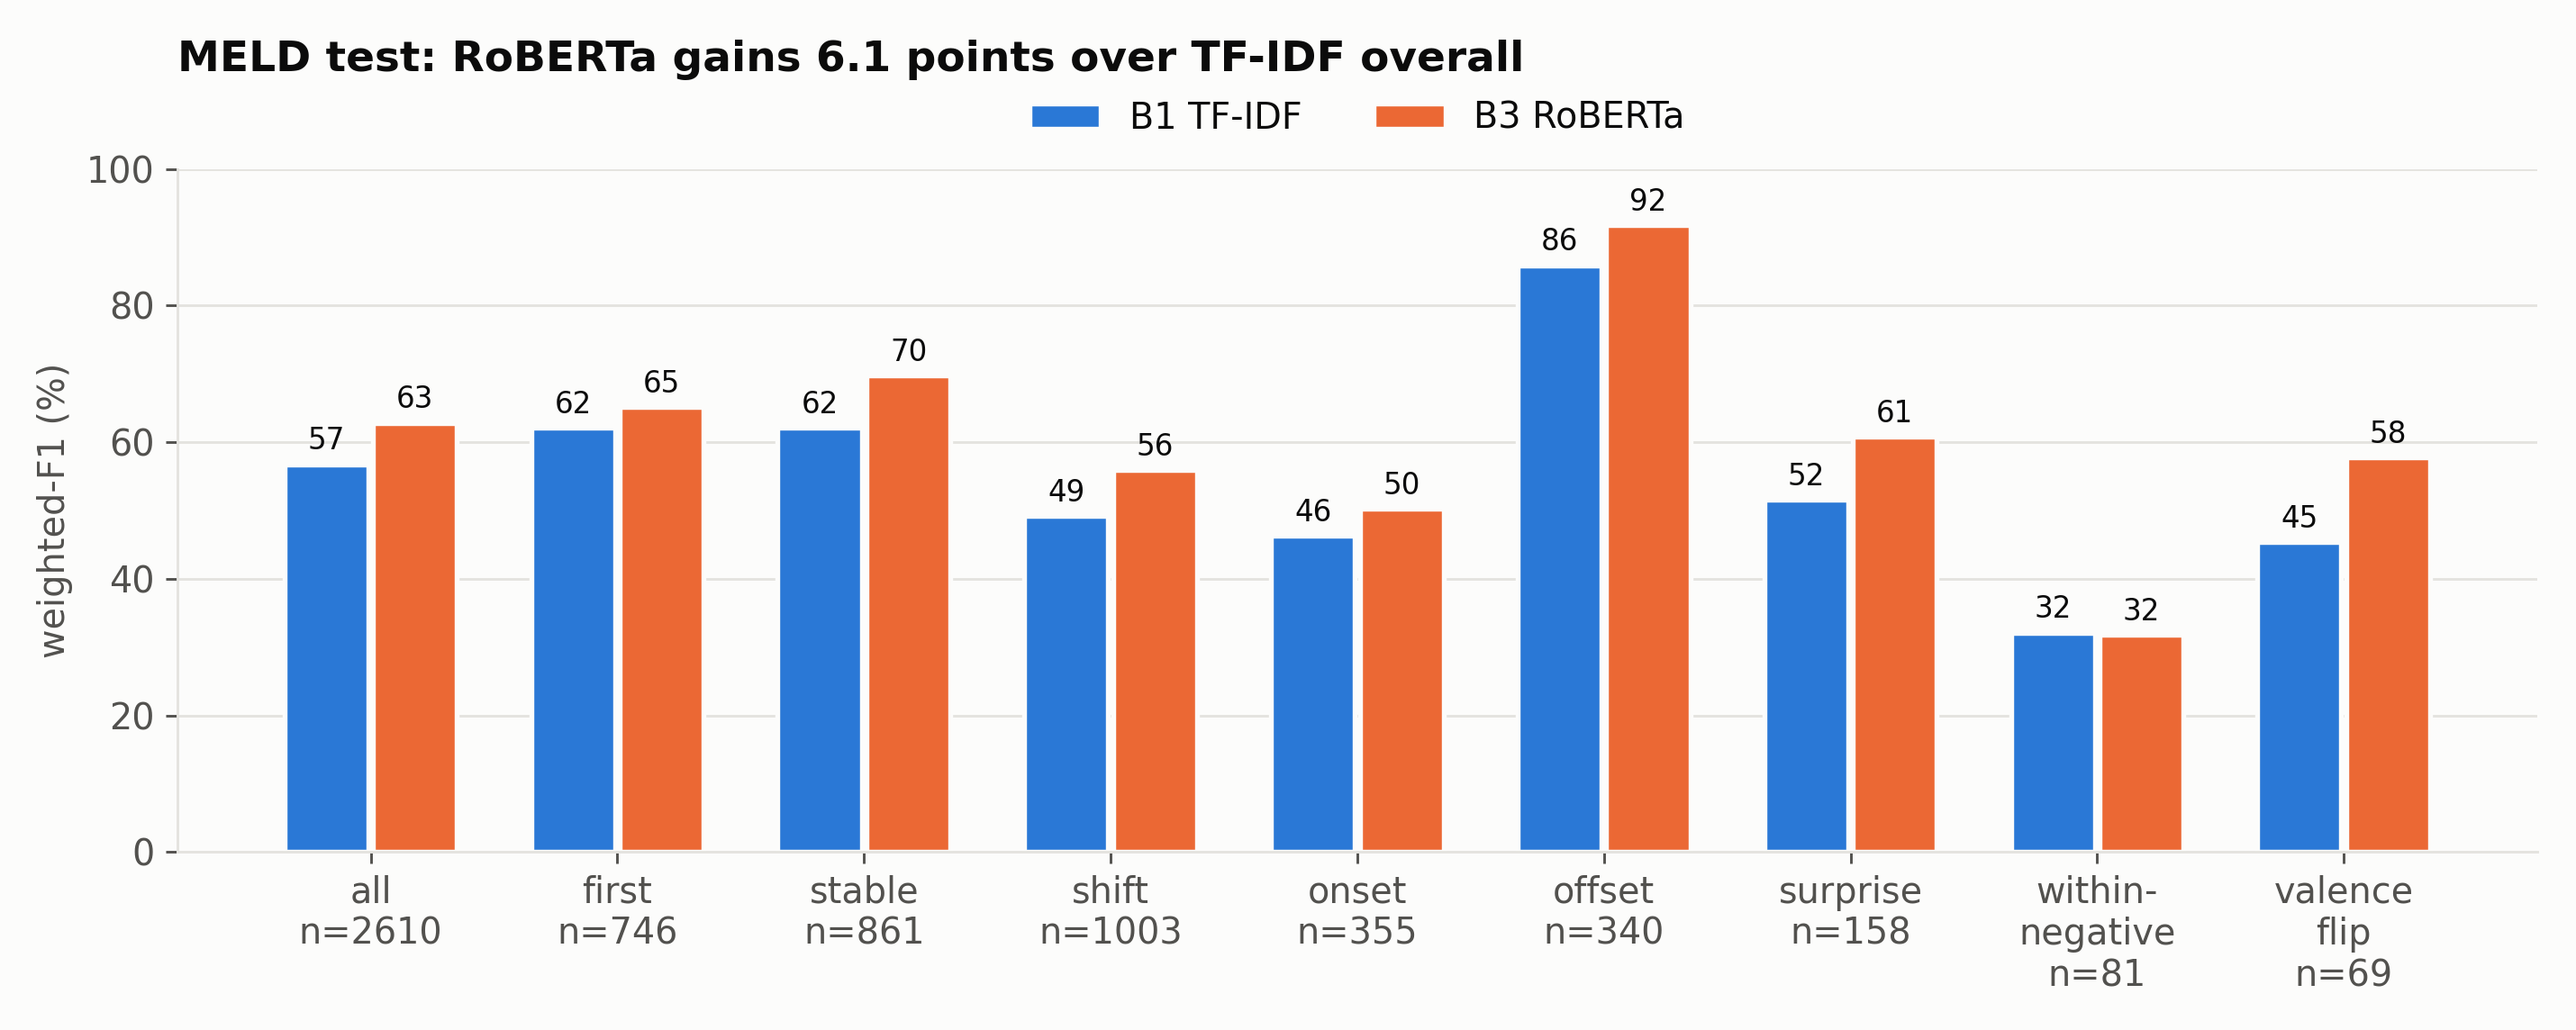

In [10]:
!python scripts/analyse_b3.py --out "{OUT}" 2>&1 | tail -8
display(Image(str(FIG / "meld_b1_vs_b3.png"), width=1000))

In [11]:
strat = pd.read_csv(FIG / "meld_strata.csv")
strat.assign(weighted_f1=100 * strat.weighted_f1, macro_f1=100 * strat.macro_f1)[["group", "n", "weighted_f1", "macro_f1"]]

,group,n,weighted_f1,macro_f1
0,all,2610.0,62.85,40.56
1,stratum:first,746.0,65.18,40.11
2,stratum:stable,861.0,69.73,38.72
3,stratum:shift,1003.0,55.91,40.53
4,shift_type:onset,355.0,50.25,30.53
5,shift_type:offset,340.0,91.81,13.12
6,shift_type:surprise,158.0,60.84,33.49
7,shift_type:within_negative,81.0,31.78,11.31
8,shift_type:valence_flip,69.0,57.77,28.23


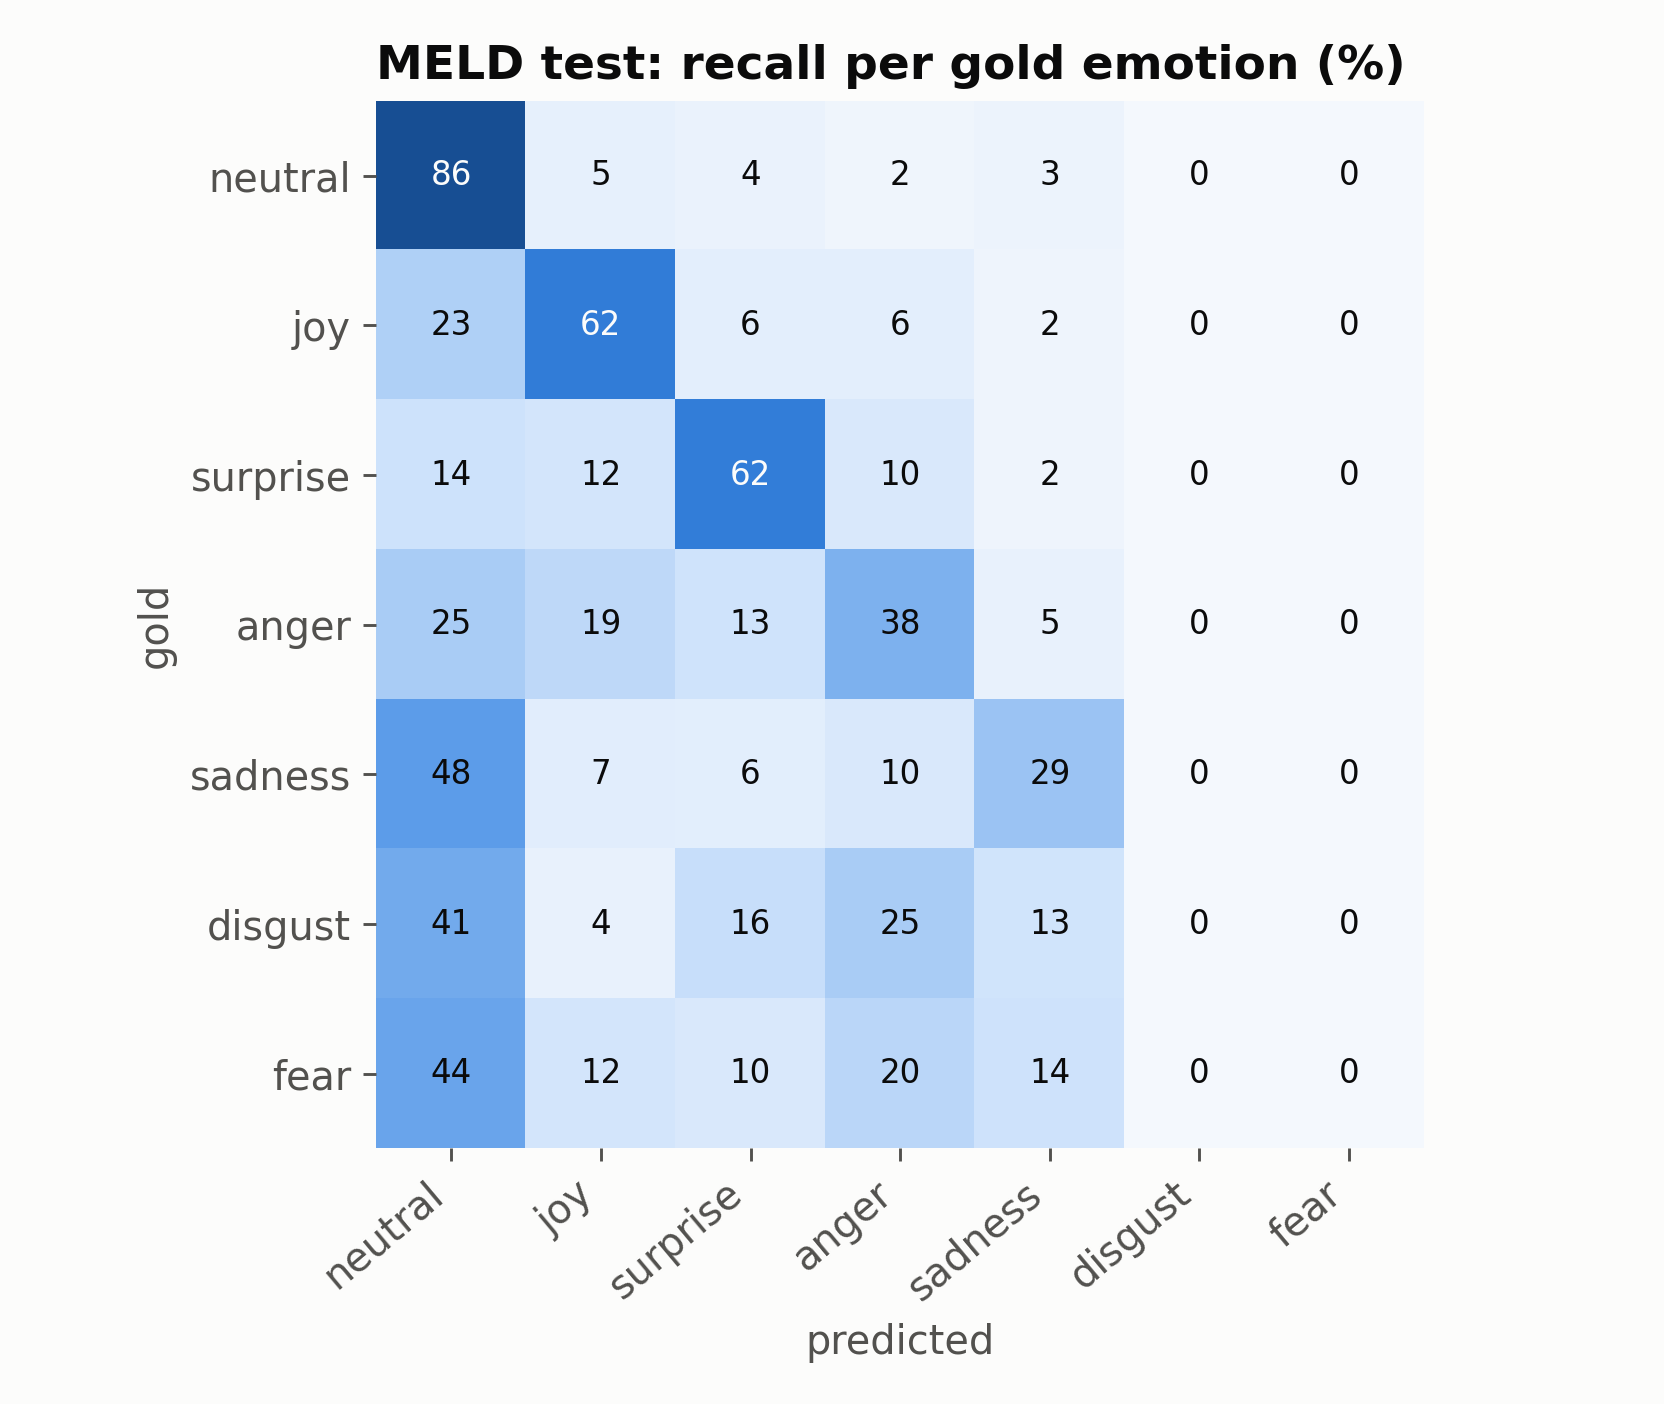

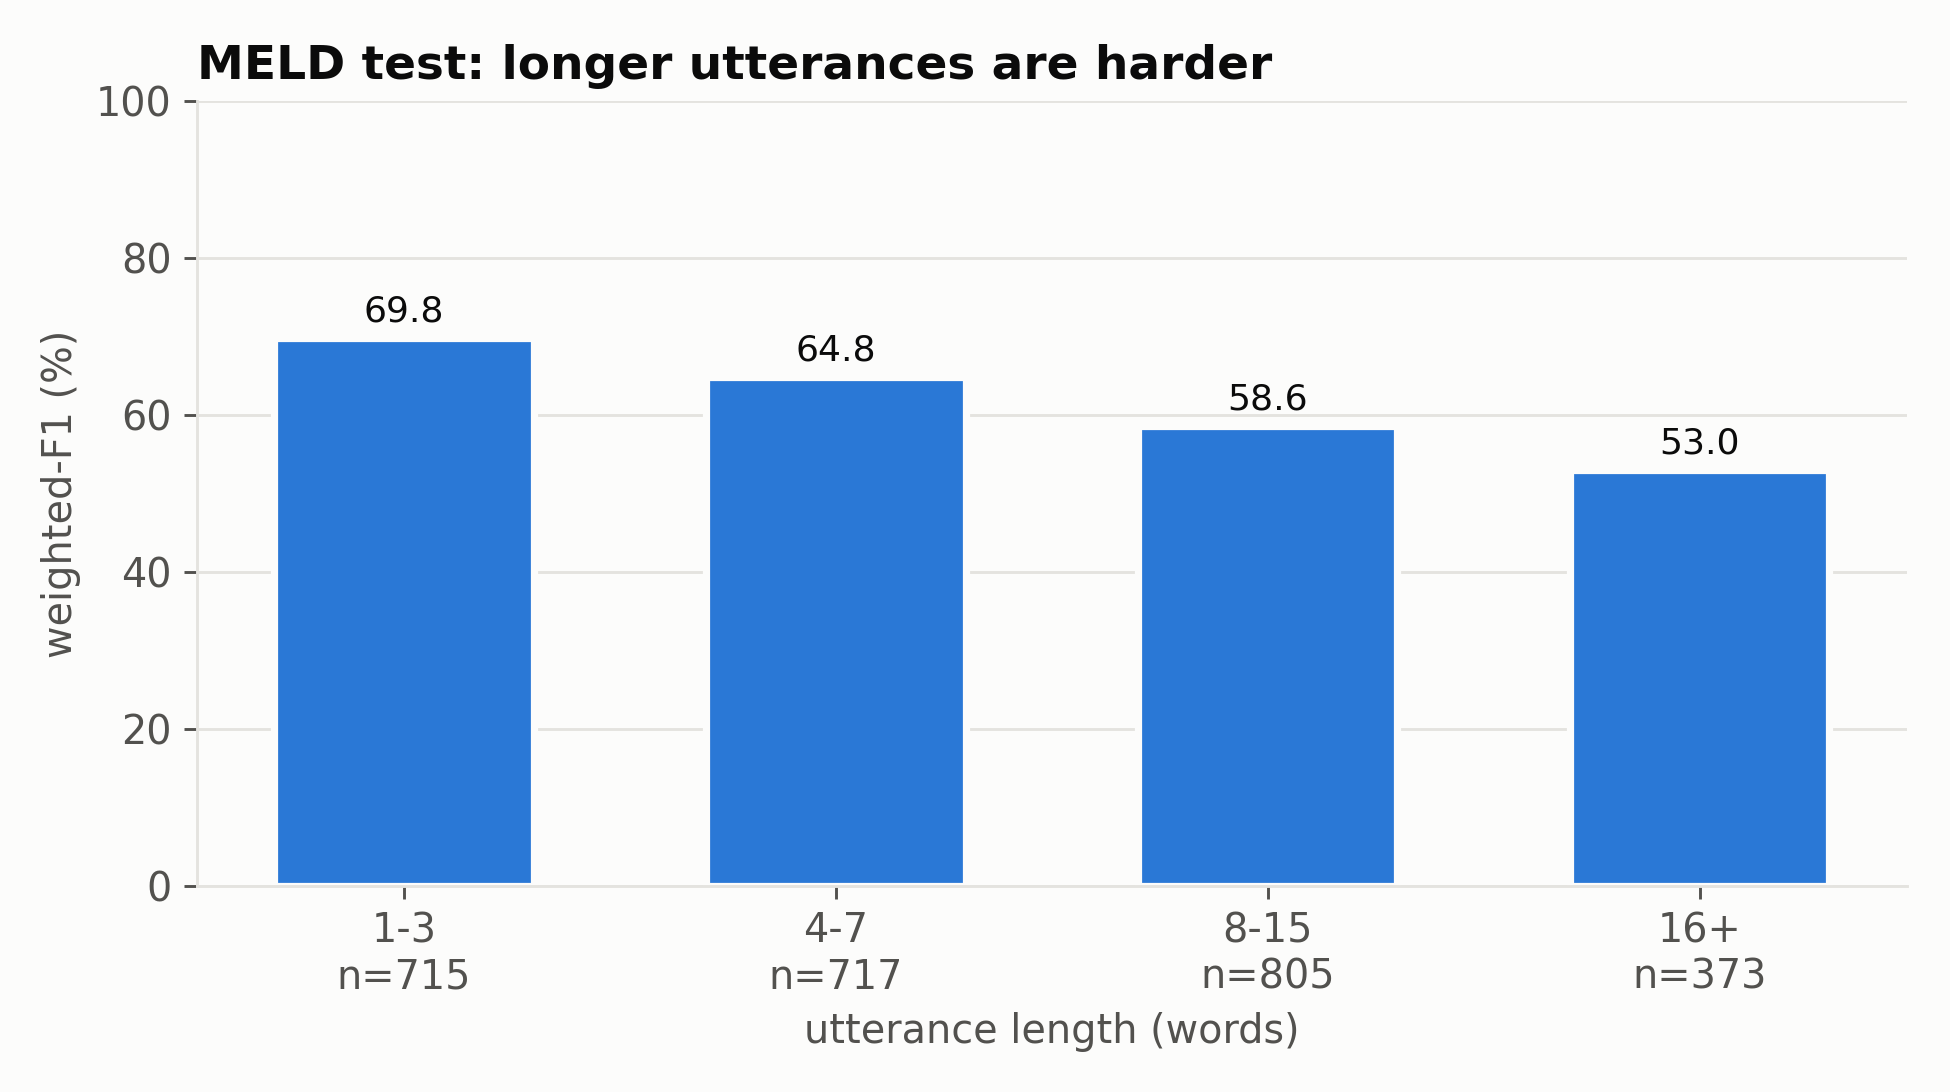

In [12]:
display(Image(str(FIG / "meld_confusion.png"), width=520))
display(Image(str(FIG / "meld_length.png"), width=620))

In [13]:
preds = [pd.read_csv(f) for f in sorted((OUT / "predictions").glob("b3_meld_test_seed*.csv"))]
print("Derived shift detection (predicted label vs the speaker's previous predicted label), first seed:")
M.derived_shift_detection(preds[0])

Derived shift detection (predicted label vs the speaker's previous predicted label), first seed:


{'n': 1864,
 'base_rate': 0.5380901287553648,
 'shift_f1': 0.7167745146839224,
 'predicted_shift_rate': 0.5396995708154506}

## 6. Inside the model: Integrated Gradients

For one utterance, each word's embedding is faded in from the padding embedding (32 steps); a word's
attribution is how much the predicted emotion's score rises along the way. The attributions add up to
the change in score, so unlike attention weights they are faithful to the model.

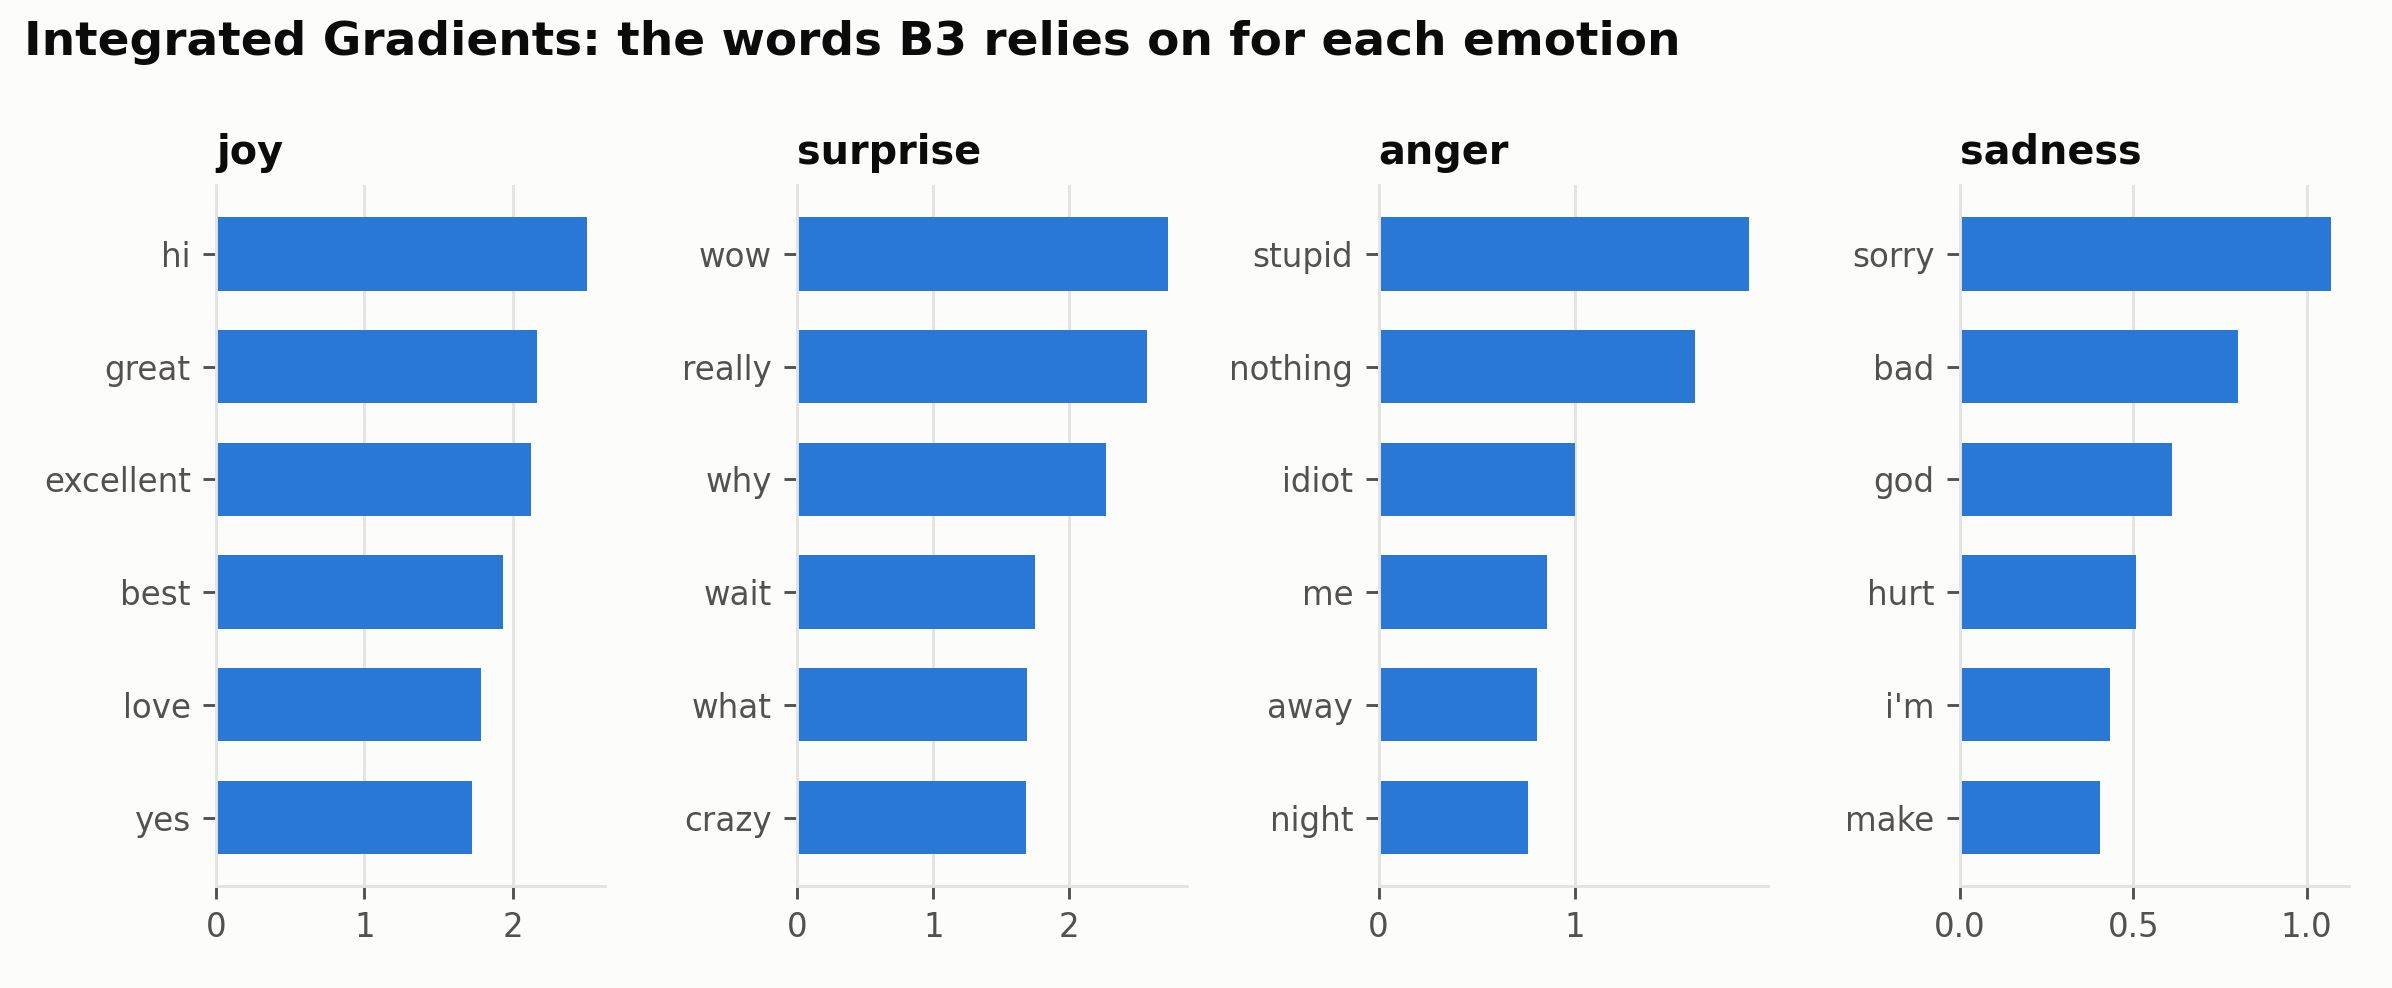

In [14]:
display(Image(str(FIG / "meld_ig_top_words.png"), width=1000))
display(HTML((FIG / "meld_ig_examples.html").read_text()))

## 7. Try it

In [15]:
m = RobertaUtterance.load(OUT / "models/b3_meld")
lines = ["Oh my God! You got the job?!", "Yeah.", "I'm so sorry about your dad.",
         "Get out of my apartment!", "Ew, what is that smell?", "I'm scared, what if he finds out?"]
p = m.predict_proba(lines)
pd.DataFrame({"utterance": lines, "B3 says": m.predict(lines), "confidence": p.max(1).round(2)})

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,utterance,B3 says,confidence
0,Oh my God! You got the job?!,surprise,0.93
1,Yeah.,neutral,0.96
2,I'm so sorry about your dad.,sadness,0.74
3,Get out of my apartment!,anger,0.70
4,"Ew, what is that smell?",surprise,0.69
5,"I'm scared, what if he finds out?",sadness,0.39


## 8. Transfer: MELD → DailyDialog (E8)

In [16]:
pd.read_csv(FIG / "transfer_dailydialog.csv")

,model,split,n,micro_f1_no_neutral,macro_f1,weighted_f1,derived_shift_f1
0,trained on MELD (transfer),test_dedup,7019,40.92,32.00,80.15,42.61
1,trained on MELD (transfer),test,7740,40.06,31.58,79.62,41.85
2,trained on DailyDialog,test_dedup,7019,55.34,39.69,84.80,52.28
3,trained on DailyDialog,test,7740,55.30,41.52,84.65,51.72


## 9. Efficiency (E9)

The demo needs < 300 ms per utterance on a laptop CPU. Latency is one utterance per call.

In [17]:
rows = []
for ds in ["meld", "dailydialog"]:
    e = json.loads((OUT / f"reports/b3/{ds}/summary.json").read_text())["efficiency"]
    rows.append({"trained on": ds, "parameters (M)": round(e["parameters"] / 1e6, 1), "model files (MB)": e["model_dir_mb"],
                 "train min / seed": round(e["train_seconds"]["mean"] / 60, 1),
                 "CPU median ms": round(e["latency_one_utterance_cpu"]["median_ms"], 1),
                 "CPU p95 ms": round(e["latency_one_utterance_cpu"]["p95_ms"], 1),
                 "GPU utt/s": round(e["batch_throughput"]["utterances_per_second"])})
pd.DataFrame(rows)

,trained on,parameters (M),model files (MB),train min / seed,CPU median ms,CPU p95 ms,GPU utt/s
0,meld,124.7,502.2,4.2,105.8,138.5,488
1,dailydialog,124.7,502.2,14.0,106.8,149.7,329


## Takeaways

* B3 reaches **62.85 ± 0.28 weighted-F1 on MELD** (B1: 56.78) and **55.34 ± 0.35 micro-F1 (excl. neutral) on
  de-duplicated DailyDialog** (B1: 53.03), with five seeds. On MELD that is about 1.7 points under EmoBERTa
  (RoBERTa-*large* with context, 64.6), close to what the proposal expected for the base model without context.
* **The shift gap survives without context.** B3 scores 69.7 on stable turns and 55.9 on shift turns (B1: 62.1 vs 49.1).
  A model that never sees the previous turn cannot copy the previous emotion, so part of the gap is in the text
  itself: turning points are harder to read from the utterance alone. Context models (B4, ShiftAware) should be
  judged on how much of the remaining gap they close.
* B3 gains on almost every shift type (valence flips +12.4, surprise +9.3), but **within-negative shifts stay at
  ~32** for both models: anger → sadness is hard to tell from text alone.
* **Rare classes are the weak spot.** With plain cross-entropy B3 almost never predicts disgust or fear on MELD
  (0–6 such predictions per seed for 118 gold cases; F1 0 on the first seed), and on DailyDialog its macro-F1 (39.7) is below B1's class-weighted SVM (46.2).
  Class weights or focal loss are the B4+ fallback in the proposal.
* Longer utterances are harder (69.8 weighted-F1 for 1–3 words vs 53.0 for 16+), mostly because short turns
  are dominated by neutral and surprise ("Oh!", "Really?").
* Integrated Gradients finds readable cues that agree with B1's n-grams: surprise ← *wow, really, what*;
  joy ← *hi, great, excellent, love*; anger ← *stupid, idiot*; sadness ← *sorry, hurt*.
* **Transfer (E8):** the MELD model scores 40.9 micro-F1 on DailyDialog vs 55.3 when trained there, and its
  derived shift F1 drops from 52.3 to 42.6. It predicts a shift on 27% of DailyDialog turns against a true
  rate of 18% (the DailyDialog-trained model: 24%), which is what hypothesis H6 expects from MELD's 54% shift rate.
* **Efficiency:** 124.7M parameters, 502 MB on disk, about 106 ms per utterance on a 2-core CPU — inside the
  demo's 300 ms budget; DistilRoBERTa would roughly halve that.


In [18]:
# Colab only: one zip of the results for the repo (the models stay in the Drive folder for the team).
if "google.colab" in sys.modules:
    subprocess.run(f'cd "{OUT}" && zip -qr b3_results.zip predictions reports', shell=True, check=True)
    print("saved", OUT / "b3_results.zip", "| models:", sorted(p.name for p in (OUT / "models").iterdir()))

saved /content/drive/MyDrive/EE6405_EmotionShift/b3_out/b3_results.zip | models: ['b3_dailydialog', 'b3_meld']
